# Pretrained features: does pretraining on every element close the gap?

In the `cgcnn` experiment a graph network trained from scratch beat gradient boosting on descriptors wherever the elements of the test materials were known, and lost to it on compounds of an element it had never seen. Universal interatomic potentials are pretrained on hundreds of thousands to millions of DFT calculations that cover nearly the whole periodic table. Used as frozen feature extractors, do they carry what a model trained on the JARVIS data alone cannot learn?

Three pretrained models, chosen for what they were trained on:

| Model | Architecture | Pretraining data | License |
|---|---|---|---|
| MACE-MP-0b3, medium (Batatia et al., arXiv:2401.00096) | equivariant message passing (MACE), 2 interactions | MPtrj: 1.58 million frames of Materials Project relaxations, PBE/PBE+U | MIT |
| CHGNet 0.3.0 (Deng et al., Nat. Mach. Intell. 5, 1031, 2023) | invariant graph network with bond angles, 4 convolutions | MPtrj | BSD-3-Clause |
| Orb v3, conservative, unlimited neighbors, OMat24 (Rhodes et al., arXiv:2504.06231) | graph network without built-in symmetry, 5 message-passing steps | OMat24 (AIMD subset): perturbed and molecular-dynamics structures derived from Alexandria, PBE/PBE+U | Apache-2.0 |

Each model turns every atom into a vector, the one its energy readout reads; a structure is described by the mean and the standard deviation of its atoms' vectors (`materials_ml_primer.pretrained`). The downstream model is the bootstrap ensemble of five gradient-boosting models of the `uncertainty` experiment, with the same settings and on exactly the same training, validation, calibration and test materials, so that the only difference from that experiment is the input: features of a pretrained model instead of 150 composition and structure descriptors.

**A complication: the pretraining data overlap the test data.** 77 % of the 55 712 JARVIS materials (43 040) were started from a Materials Project structure, and MPtrj contains the Materials Project relaxations; 83 % of the fluorides are among them. A model pretrained on MPtrj has therefore seen many of the test compounds, computed with another functional (PBE instead of OptB88vdW), even when the downstream model has never seen their element. Section 4 separates the test materials by their source to see whether that matters.

In [1]:
import contextlib
import importlib.util
import io
import json
import logging
import subprocess
import sys
import time
import warnings
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy import stats

import runs
from materials_ml_primer import data, pretrained, splits
from materials_ml_primer import uncertainty as uq

QUICK = False       # True only in a test run of this notebook: use the cache, compute nothing
ALPHA = 0.1
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SPLITS = ["random", "chemical-system groups", "prototype groups", "leave one element out", "prospective"]
NAMES = {"descriptors": "descriptors (150)", "mace-mp-0b3": "MACE-MP-0b3", "chgnet-0.3.0": "CHGNet",
         "orb-v3-omat": "Orb v3 (OMat24)"}
COLORS = {"descriptors": "0.45", "mace-mp-0b3": "C0", "chgnet-0.3.0": "C2", "orb-v3-omat": "C3"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10})
warnings.filterwarnings("ignore", category=UserWarning)
summary = []


@contextlib.contextmanager
def quiet():
    # The packages print loading messages, deprecation warnings and cache paths; keep only this notebook's output.
    logging.disable(logging.CRITICAL)
    try:
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()), \
                warnings.catch_warnings():
            warnings.simplefilter("ignore")
            yield
    finally:
        logging.disable(logging.NOTSET)


print(f"torch {torch.__version__}, device {torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'cpu'}")

torch 2.15.0+cu132, device NVIDIA GeForce RTX 3060


In [2]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", "--color=no", "-p", "no:cacheprovider",
                    "-W", "ignore", "../../tests/test_pretrained.py"], capture_output=True, text=True)
print(r.stdout[-1500:])

...................                                                      [100%]
19 passed in 15.86s



The tests check, for each model: the documented feature dimension; that a structure gets the same features in a batch as alone; that the features ignore the order of the atoms and the choice of the unit cell (a supercell); that MACE's and CHGNet's features ignore rotations and reflections; and that the extraction runs each model as its package does (MACE: the calculator's `get_descriptors` and energy; CHGNet: its own crystal feature, which is the sum of the atom features, and its energy; Orb: the energy of its ASE calculator, and a nearly rotation-invariant energy).

## 1. Data and features

In [3]:
t0 = time.perf_counter()
d = runs.load()
UQR = runs._uncertainty_runs()
TASKS = UQR.tasks(d)
print(f"{len(d['y'])} materials (2021.8.18) and {len(d['y_add'])} added up to 2025.9.24; {len(TASKS)} test sets "
      f"({time.perf_counter() - t0:.0f} s)")
FEAT = {}
for v in runs.VARIANTS:
    parts = [runs.features(d, v, part, compute=not QUICK, device=DEVICE, log=lambda m: None) for part in runs.parts(v)]
    if any(p is None for p in parts):
        print(f"{v}: features not computed")
        continue
    FEAT[v] = parts
    X = np.vstack([p["X"] for p in parts])
    iso = sum(int(p["isolated_atoms"]) for p in parts) if "chgnet" in v else None
    print(f"{v:22s} {X.shape[1]:4d} features, {sum(float(p['seconds']) for p in parts) / 60:5.1f} min on the GPU, "
          f"non-finite values: {int((~np.isfinite(X)).sum())}" + (f", atoms without a neighbor within 6 Å: {iso}" if iso is not None else ""))

55712 materials (2021.8.18) and 38190 added up to 2025.9.24; 109 test sets (111 s)


mace-mp-0b3             512 features,   5.1 min on the GPU, non-finite values: 0


chgnet-0.3.0            128 features,  13.8 min on the GPU, non-finite values: 0, atoms without a neighbor within 6 Å: 13


orb-v3-omat             512 features,   4.5 min on the GPU, non-finite values: 0


orb-v3-omat-rotated     512 features,   2.5 min on the GPU, non-finite values: 0


In [4]:
def source(rec):
    ref = str(rec.get("reference", ""))
    for prefix, name in (("mp-", "Materials Project"), ("mvc-", "Materials Project (mvc)"), ("agm", "Alexandria"),
                         ("auid-", "AFLOW"), ("JQE-", "JQE (not documented)"), ("JVASP-", "JARVIS")):
        if ref.startswith(prefix):
            return name
    return "other"


SRC = np.array([source(r) for r in d["records"]])
SRC_ADD = np.array([source(r) for r in d["added"]])
# the unit of the cluster bootstrap in sections 4 and 5: the prototype label for the prototype split (whose test
# sets are whole structure types), the chemical system for every other split
SYS = np.array(d["system"])
SYS_ADD = np.array(["-".join(splits.chemical_system(data.structure_arrays(r["atoms"])[2])) for r in d["added"]])
PROTO = np.array(d["proto"])


def cluster_units(t):
    if t.split == "prototype groups":
        return PROTO[t.test]
    return (SYS_ADD if t.added else SYS)[t.test]
has_icsd = np.array([bool(str(r.get("icsd", "")).strip()) for r in d["records"]])
print(f"{'source of the starting structure':32s} {'2021 snapshot':>14s} {'with an ICSD entry':>19s} {'added later':>12s}")
for s in ["Materials Project", "Materials Project (mvc)", "Alexandria", "AFLOW", "JQE (not documented)", "JARVIS", "other"]:
    m = SRC == s
    share = f"{has_icsd[m].mean():.0%}" if m.any() else "-"
    print(f"{s:32s} {m.sum():14d} {share:>19s} {np.sum(SRC_ADD == s):12d}")

source of the starting structure  2021 snapshot  with an ICSD entry  added later
Materials Project                         43040                 43%        14305
Materials Project (mvc)                    1518                  0%           47
Alexandria                                    0                   -         4492
AFLOW                                      6529                  0%         4194
JQE (not documented)                       3359                  0%         7920
JARVIS                                      483                  0%         4086
other                                       783                  0%         3146


JARVIS records where each starting structure came from in the field `reference` (`mp-…`, `auid-…`, `agm…`, …). MPtrj, the pretraining set of MACE-MP-0b3 and CHGNet, holds the Materials Project relaxations (`mp-` identifiers); OMat24, the pretraining set of Orb, is derived from Alexandria (`agm` identifiers), which itself started from Materials Project and other structures. Whether a given compound is in MPtrj or OMat24 is not checked here (that would need the full data sets, several GB); the source is a proxy.

## 2. Verification on JARVIS structures

The tests above use small random cells. Here the same comparisons with the packages' own outputs run on 100 random JARVIS structures, and the invariances are measured: each structure is turned by a random rotation, by a rotation combined with a reflection, its atoms are shuffled and it is doubled into a supercell, and the change of each feature is divided by the spread of that feature between materials.

In [5]:
from pymatgen.io.ase import AseAtomsAdaptor

rng = np.random.default_rng(0)
pick = rng.choice(len(d["records"]), 100, replace=False)
cells = [data.structure_arrays(d["records"][i]["atoms"]) for i in pick]
base = [pretrained.to_atoms(*c) for c in cells]


def moved(kind, k, c):
    lat, frac, sp = c
    if kind in ("rotation", "reflection"):
        q = runs.rotation(10_000 + k)
        if kind == "reflection":
            q = q @ np.diag([-1.0, 1.0, 1.0])
        return pretrained.to_atoms(lat @ q.T, frac, sp)
    if kind == "atom order":
        p = np.random.default_rng(k).permutation(len(sp))
        return pretrained.to_atoms(lat, frac[p], [sp[j] for j in p])
    sup = np.vstack([frac * [0.5, 1, 1], (frac + [1, 0, 0]) * [0.5, 1, 1]])
    return pretrained.to_atoms(lat * [[2], [1], [1]], sup, list(sp) * 2)


invariance, checks = {}, []
for name in runs.MODELS:
    if QUICK:
        break
    with quiet():
        ex = pretrained.load(name, DEVICE)
        with torch.no_grad():
            f, e = ex(base[:30])
        if name == "mace-mp-0b3":
            check = max(float(np.abs(f[k] - ex.calc.get_descriptors(base[k])).max()) for k in range(30))
            what = "largest difference from MACECalculator.get_descriptors"
        elif name == "chgnet-0.3.0":
            p = ex.model.predict_structure([AseAtomsAdaptor.get_structure(a) for a in base[:30]], task="e",
                                           return_crystal_feas=True)
            check = max(max(float(np.abs(f[k].sum(0) - p[k]["crystal_fea"]).max()), abs(float(p[k]["e"]) - e[k]))
                        for k in range(30))
            what = "largest difference from CHGNet's crystal feature (sum) and energy"
        else:
            from orb_models.forcefield.inference.calculator import ORBCalculator

            calc = ORBCalculator(ex.model, ex.adapter, device=DEVICE)
            ref = []
            for a in base[:30]:
                b = a.copy()
                b.calc = calc
                ref.append(b.get_potential_energy() / len(b))
            check = float(np.abs(ex.energy(base[:30]) - np.array(ref)).max())
            what = "largest difference of the batched energy from ORBCalculator (eV/atom)"
        checks.append(f"{name}: {what}: {check:.1e}")
        f0, _, _ = pretrained.featurize(ex, base)
        spread = f0.std(axis=0) + 1e-12
        for kind in ("atom order", "supercell", "rotation", "reflection"):
            f1, _, _ = pretrained.featurize(ex, [moved(kind, k, c) for k, c in enumerate(cells)])
            rel = np.abs(f1 - f0) / spread
            invariance[(name, kind)] = (float(np.median(rel)), float(np.percentile(rel, 99)), float(rel.max()))
        if name == "orb-v3-omat":
            e0 = ex.energy(base)
            e1 = ex.energy([moved("rotation", k, c) for k, c in enumerate(cells)])
            orb_energy_change = float(np.abs(e1 - e0).max())
        del ex
        torch.cuda.empty_cache()
print("\n".join(checks))
print(f"\n{'model':14s} {'change':12s} {'median':>9s} {'99th pct':>9s} {'largest':>9s}   (feature change / spread between materials)")
for (name, kind), v in invariance.items():
    print(f"{name:14s} {kind:12s} {v[0]:9.1e} {v[1]:9.1e} {v[2]:9.1e}")
if invariance:
    print(f"Orb: largest change of the energy under the rotations: {orb_energy_change:.1e} eV/atom")
    summary.append(("Orb features under rotation: 99th percentile of change / spread",
                    f"{invariance[('orb-v3-omat', 'rotation')][1]:.2f}", "0 for an invariant model", "this notebook"))

mace-mp-0b3: largest difference from MACECalculator.get_descriptors: 3.3e-06
chgnet-0.3.0: largest difference from CHGNet's crystal feature (sum) and energy: 7.6e-06
orb-v3-omat: largest difference of the batched energy from ORBCalculator (eV/atom): 9.1e-07

model          change          median  99th pct   largest   (feature change / spread between materials)
mace-mp-0b3    atom order     1.7e-07   1.4e-06   6.7e-06
mace-mp-0b3    supercell      3.4e-07   3.5e-06   1.5e-05
mace-mp-0b3    rotation       5.0e-07   5.9e-06   3.0e-05
mace-mp-0b3    reflection     4.6e-07   6.1e-06   2.7e-05
chgnet-0.3.0   atom order     2.3e-07   8.4e-06   5.9e-05
chgnet-0.3.0   supercell      3.6e-07   8.8e-06   6.2e-05
chgnet-0.3.0   rotation       7.1e-07   1.0e-05   3.3e-05
chgnet-0.3.0   reflection     6.8e-07   1.1e-05   5.1e-05
orb-v3-omat    atom order     5.2e-07   7.1e-06   3.6e-04
orb-v3-omat    supercell      1.1e-06   2.7e-05   1.3e-03
orb-v3-omat    rotation       3.3e-03   4.1e-01   2.8e+00

MACE and CHGNet are invariant by construction, and their features change only at the level of float32 rounding. Orb is not: it learns rotational symmetry from data. Its energy changes by about a meV per atom under a rotation, but some of its latent features change by as much as their spread between materials, so the features depend on how a structure is oriented, which the energy readout learned to ignore. JARVIS stores every structure in one orientation; section 5 checks whether random orientations change the results.

## 3. Accuracy under distribution shift

Expected: on the random split the pretrained features should be at least as good as the descriptors (they were pretrained on energies); if pretraining covers the chemistry that the JARVIS training set lacks, the gain should be largest when an element is held out.

The MAE of a split is the mean over its test sets. The last column is the ensemble of five CGCNNs of the `cgcnn` experiment on the same test sets. That experiment held out only 12 of the 78 elements, so its leave-one-element-out MAE stands in a separate row averaged over those 12 elements (element by element further below); the row of all 78 has no CGCNN value.

In [6]:
desc = {t.key: UQR.result(d, t, "cpu", compute=False) for t in TASKS}
missing_desc = [k for k, v in desc.items() if v is None]
R = {}
counts = Counter()
for t in TASKS:
    if desc[t.key] is None:
        continue
    r = {"key": t.key, "split": t.split, "test": t.test, "added": t.added, "y_cal": d["y"][t.cal],
         "y_test": (d["y_add"] if t.added else d["y"])[t.test],
         "src": (SRC_ADD if t.added else SRC)[t.test], "unit": cluster_units(t),
         "mu": {"descriptors": desc[t.key][0]["test_mu_ens"]}, "sd": {"descriptors": desc[t.key][0]["test_sd_ens"]},
         "cal_mu": {"descriptors": desc[t.key][0]["cal_mu_ens"]}, "cal_sd": {"descriptors": desc[t.key][0]["cal_sd_ens"]}}
    for v in runs.MODELS:
        if v not in FEAT:
            continue
        res = runs.fit(d, v, t, FEAT[v], compute=not QUICK)
        if res is None:
            continue
        counts[res[1]] += 1
        r["mu"][v], r["sd"][v] = res[0]["test_mu"], res[0]["test_sd"]
        r["cal_mu"][v], r["cal_sd"][v] = res[0]["cal_mu"], res[0]["cal_sd"]
        r.setdefault("seconds", {})[v] = float(res[0]["seconds"])
        r.setdefault("iterations", {})[v] = res[0]["iterations"]
    R[t.key] = r
print(dict(counts), f"tasks: {len(R)}; descriptor results missing: {missing_desc[:5]}")
METHODS = ["descriptors"] + [v for v in runs.MODELS if all(v in r["mu"] for r in R.values())]
for v in METHODS[1:]:
    its = np.concatenate([r["iterations"][v] for r in R.values()])
    print(f"{v}: fitting time {sum(r['seconds'][v] for r in R.values()) / 3600:.1f} h (four processes at a time); "
          f"ensemble members that reached the limit of {runs.FIT_SETTINGS['max_iter']} iterations: "
          f"{np.mean(its >= runs.FIT_SETTINGS['max_iter']):.0%}")

{'cached': 327} tasks: 109; descriptor results missing: []
mace-mp-0b3: fitting time 42.9 h (four processes at a time); ensemble members that reached the limit of 2500 iterations: 37%
chgnet-0.3.0: fitting time 10.4 h (four processes at a time); ensemble members that reached the limit of 2500 iterations: 77%
orb-v3-omat: fitting time 42.9 h (four processes at a time); ensemble members that reached the limit of 2500 iterations: 24%


In [7]:
def mae(r, m):
    return float(np.mean(np.abs(r["mu"][m] - r["y_test"])))


def r2(r, m):
    y = r["y_test"]
    return float(1 - np.sum((r["mu"][m] - y) ** 2) / np.sum((y - y.mean()) ** 2))


cg = json.loads((runs.HERE.parent / "cgcnn" / "cgcnn_results.json").read_text(encoding="utf-8"))
# CGCNN held out only 12 elements: its leave-one-element-out MAE is compared on those 12, not on all 78
LOEO, LOEO12 = "leave one element out", "leave one element out, CGCNN's 12"
CG_ELEMENTS = [e["element"] for e in cg["elements"]]
ROWS = SPLITS[:4] + [LOEO12] + SPLITS[4:]


def rows_of(split):
    if split == LOEO12:
        return [R[f"element-{e}"] for e in CG_ELEMENTS if f"element-{e}" in R]
    return [r for r in R.values() if r["split"] == split]


def cgcnn_mae(split, method="CGCNN (ensemble of 5)"):
    if split == LOEO:
        return np.nan
    return cg["mae"].get(LOEO if split == LOEO12 else split, {}).get(method, [np.nan])[0]


mae_table = {}
print(f"{'split':34s} {'tasks':>5s} " + " ".join(f"{NAMES[m]:>18s}" for m in METHODS) + f" {'CGCNN ens.':>11s}")
for split in ROWS:
    rs = rows_of(split)
    mae_table[split] = {m: float(np.mean([mae(r, m) for r in rs])) for m in METHODS}
    print(f"{split:34s} {len(rs):5d} " + " ".join(f"{mae_table[split][m]:18.4f}" for m in METHODS)
          + f" {cgcnn_mae(split):11.4f}")
# the descriptor model is the "HGB (ensemble of 5)" of the cgcnn experiment: same predictions, same MAE
hgb_check = {s: (mae_table[s]["descriptors"], cgcnn_mae(s, "HGB (ensemble of 5)")) for s in ROWS if s != LOEO}
print("descriptors here vs HGB in cgcnn_results.json: "
      + ", ".join(f"{s} {a:.4f} / {b:.4f}" for s, (a, b) in hgb_check.items()))
print("\nMAE relative to the random split:")
for split in ROWS:
    print(f"  {split:34s} " + "  ".join(f"{NAMES[m]} {mae_table[split][m] / mae_table['random'][m]:.2f}" for m in METHODS))
print("\ntest sets on which the features beat the descriptors:")
for split in ROWS:
    rs = rows_of(split)
    print(f"  {split:34s} " + "  ".join(f"{NAMES[m]} {sum(mae(r, m) < mae(r, 'descriptors') for r in rs)} of {len(rs)}"
                                       for m in METHODS[1:]))
for m in METHODS[1:]:
    summary.append((f"MAE random split, {NAMES[m]} features (descriptors {mae_table['random']['descriptors']:.3f})",
                    f"{mae_table['random'][m]:.4f}", f"CGCNN {cg['mae']['random']['CGCNN (ensemble of 5)'][0]:.4f}",
                    "this repository"))

split                              tasks  descriptors (150)        MACE-MP-0b3             CHGNet    Orb v3 (OMat24)  CGCNN ens.
random                                10             0.0878             0.0840             0.0752             0.0794      0.0563
chemical-system groups                10             0.1054             0.1001             0.0927             0.0927      0.0619
prototype groups                      10             0.1567             0.1110             0.0961             0.1107      0.0837
leave one element out                 78             0.1596             0.1461             0.1477             0.1369         nan
leave one element out, CGCNN's 12     12             0.3032             0.2576             0.2811             0.3059      0.3823
prospective                            1             0.1165             0.1089             0.1031             0.1048      0.0731
descriptors here vs HGB in cgcnn_results.json: random 0.0878 / 0.0878, chemical-system groups 0.1

### The pretrained energy itself

The models were pretrained to predict the DFT energy, and MACE's and CHGNet's energy per atom was stored with their features (Orb's energy needs a gradient pass and was not computed, `pretrained.load`). A formation energy is an energy per atom minus composition-weighted reference energies of the elements, so a linear model $y \approx a E + \sum_i c_i x_i$ ($E$: the model's energy per atom, $x_i$: the atomic fraction of element $i$), fitted by least squares on the training materials of each test set, turns the predicted energy into a formation energy with one correction per element. The corrections also absorb what is systematic per element in the difference between the pretraining data (PBE, and PBE+U for oxides and fluorides of some transition metals) and JARVIS (OptB88vdW). If this baseline comes close to gradient boosting on the features, what the features add is mostly the energy the model learned; if it is far behind, the features carry more than the energy. With an element held out the correction of that element has no training data, so that split is left out; materials of the other splits with an element that no training material has are kept and counted.

One correction per element cannot undo a correction that depends on the compound: Materials Project mixes PBE and PBE+U energies with the MP2020 scheme, which adds a fixed energy per oxygen or fluorine atom and, in oxides and fluorides, per atom of a +U metal (Wang et al., *Sci. Rep.* **11**, 15496, 2021). Whether a model learned corrected or uncorrected energies shows in the difference between the two models' energies: regressed on the fractions of the corrected species, it should give the MP2020 values if one model learned corrected energies and the other did not.

In [8]:
ELEMENTS = sorted({s for recs in (d["records"], d["added"]) for rec in recs for s in data.structure_arrays(rec["atoms"])[2]})
COL = {e: i for i, e in enumerate(ELEMENTS)}


def fractions(records):
    F = np.zeros((len(records), len(ELEMENTS)))
    for i, rec in enumerate(records):
        for s, n in data.composition(data.structure_arrays(rec["atoms"])[2]).items():
            F[i, COL[s]] = n
    return F / F.sum(axis=1, keepdims=True)


def energy_baseline(E_train, F_train, y_train, E_test, F_test):
    # least squares of y on [E, fractions]; the fractions sum to one, so they hold the intercept.
    # Returns the predictions and a, the coefficient of the energy (1 if the model's energy differences were JARVIS's)
    coef = np.linalg.lstsq(np.column_stack([E_train, F_train]), y_train, rcond=None)[0]
    return np.column_stack([E_test, F_test]) @ coef, float(coef[0])


FRAC, FRAC_ADD = fractions(d["records"]), fractions(d["added"])
# Orb's energy is not stored with its features (NaN): it needs a gradient pass
E_METHODS = [m for m in METHODS[1:] if np.isfinite(FEAT[m][0]["energy"]).all() and np.isfinite(FEAT[m][1]["energy"]).all()]
print("models with a stored energy:", ", ".join(NAMES[m] for m in E_METHODS),
      "| without:", ", ".join(NAMES[m] for m in METHODS[1:] if m not in E_METHODS))
E_ROWS = [s for s in ROWS if s not in (LOEO, LOEO12)]
for t in TASKS:
    if t.split == LOEO or t.key not in R:
        continue
    r = R[t.key]
    F_test = (FRAC_ADD if t.added else FRAC)[t.test]
    r["unseen_element"] = int((F_test[:, FRAC[t.train].sum(axis=0) == 0] > 0).any(axis=1).sum())
    for m in E_METHODS:
        E, E_add = FEAT[m][0]["energy"], FEAT[m][1]["energy"]
        r.setdefault("energy_mu", {})[m], r.setdefault("energy_a", {})[m] = energy_baseline(
            E[t.train], FRAC[t.train], d["y"][t.train], (E_add if t.added else E)[t.test], F_test)
energy_table = {}
print(f"\n{'split':24s} {'materials with':>14s}  MAE (eV/atom): energy + corrections / gradient boosting on the features"
      f"{'':4s} descriptors   CGCNN")
print(f"{'':24s} {'an unseen element':>14s}")
for split in E_ROWS:
    rs = rows_of(split)
    energy_table[split] = {m: float(np.mean([np.mean(np.abs(r["energy_mu"][m] - r["y_test"])) for r in rs]))
                           for m in E_METHODS}
    print(f"{split:24s} {sum(r['unseen_element'] for r in rs):14d}  "
          + "  ".join(f"{NAMES[m]} {energy_table[split][m]:.4f} / {mae_table[split][m]:.4f}" for m in E_METHODS)
          + f"{mae_table[split]['descriptors']:16.4f} {cgcnn_mae(split):7.4f}")
for m in E_METHODS:
    a = [r["energy_a"][m] for r in R.values() if "energy_a" in r]
    print(f"{NAMES[m]}: coefficient a of the energy, over the {len(a)} test sets: {min(a):.3f} to {max(a):.3f}")
for m in E_METHODS:
    summary.append((f"MAE random split, {NAMES[m]} energy + one correction per element",
                    f"{energy_table['random'][m]:.4f}", f"features {mae_table['random'][m]:.4f}", "this notebook"))

models with a stored energy: MACE-MP-0b3, CHGNet | without: Orb v3 (OMat24)



split                    materials with  MAE (eV/atom): energy + corrections / gradient boosting on the features     descriptors   CGCNN
                         an unseen element
random                                0  MACE-MP-0b3 0.1197 / 0.0840  CHGNet 0.0693 / 0.0752          0.0878  0.0563
chemical-system groups                0  MACE-MP-0b3 0.1214 / 0.1001  CHGNet 0.0700 / 0.0927          0.1054  0.0619
prototype groups                      0  MACE-MP-0b3 0.1220 / 0.1110  CHGNet 0.0703 / 0.0961          0.1567  0.0837
prospective                           0  MACE-MP-0b3 0.1293 / 0.1089  CHGNet 0.0787 / 0.1031          0.1165  0.0731
MACE-MP-0b3: coefficient a of the energy, over the 31 test sets: 0.945 to 0.963
CHGNet: coefficient a of the energy, over the 31 test sets: 1.003 to 1.012


In [9]:
# Which model learned MP2020-corrected energies? Regress E_CHGNet - E_MACE on the fractions of oxygen, fluorine and,
# in oxides and fluorides, of each +U metal, on the 2021 materials with no other MP2020-corrected anion
from pymatgen.analysis.compatibility import MP2020_COMPAT_CONFIG

MIX = MP2020_COMPAT_CONFIG["Corrections"]["GGAUMixingCorrections"]["O"]       # the same for F (pymatgen checks it)
ANION = MP2020_COMPAT_CONFIG["Corrections"]["CompositionCorrections"]
others = [e for e in ANION if e in COL and e not in ("O", "F")]
clean = (FRAC[:, [COL[e] for e in others]] == 0).all(axis=1)
has_anion = (FRAC[:, COL["O"]] > 0) | (FRAC[:, COL["F"]] > 0)
species = ["O", "F"] + list(MIX)
A = np.column_stack([FRAC[:, COL["O"]], FRAC[:, COL["F"]]] + [FRAC[:, COL[e]] * has_anion for e in MIX]
                    + [np.ones(len(FRAC))])[clean]
D = (FEAT["chgnet-0.3.0"][0]["energy"] - FEAT["mace-mp-0b3"][0]["energy"])[clean]
coef = np.linalg.lstsq(A, D, rcond=None)[0]
mp2020 = [ANION["oxide"], ANION["F"]] + [MIX[e] for e in MIX] + [0.0]
print(f"E_CHGNet - E_MACE on {clean.sum()} materials without {', '.join(others)} (eV per atom of the species)")
print(f"{'species':8s} {'fitted':>8s} {'MP2020':>8s}")
for s, c, e in zip(species + ["const"], coef, mp2020, strict=True):
    print(f"{s:8s} {c:8.3f} {e:8.3f}")
metals = (A[:, 2:-1].sum(axis=1) == 0) & (A[:, 1] == 0) & (A[:, 0] > 0)
free = (A[:, :-1].sum(axis=1) == 0)
print(f"oxides without fluorine or a +U metal ({metals.sum()}): median of (E_CHGNet - E_MACE) / x_O "
      f"{np.median(D[metals] / A[metals, 0]):+.3f} (MP2020 oxide correction {ANION['oxide']:+.3f})")
print(f"materials without any corrected species ({free.sum()}): median E_CHGNet - E_MACE {np.median(D[free]):+.3f} eV/atom")
summary.append(("E_CHGNet - E_MACE per O atom, oxides without F or a +U metal", f"{np.median(D[metals] / A[metals, 0]):+.3f}",
                f"MP2020 {ANION['oxide']:+.3f}", "pymatgen MP2020Compatibility.yaml"))

E_CHGNet - E_MACE on 34437 materials without S, Cl, Br, I, N, Se, Si, Sb, Te, H (eV per atom of the species)
species    fitted   MP2020
O          -0.659   -0.687
F          -0.445   -0.462
V          -1.701   -1.700
Cr         -2.004   -1.999
Mn         -1.667   -1.668
Fe         -2.220   -2.256
Co         -1.648   -1.638
Ni         -2.450   -2.541
W          -4.445   -4.438
Mo         -3.098   -3.202
const      -0.010    0.000
oxides without fluorine or a +U metal (4933): median of (E_CHGNet - E_MACE) / x_O -0.680 (MP2020 oxide correction -0.687)
materials without any corrected species (22050): median E_CHGNet - E_MACE -0.002 eV/atom


### Leave one element out, all 78 elements

The R² of each held-out element's compounds, with the descriptors against each pretrained model's features. Points above the diagonal are elements where the features do better.

In [10]:
elements = [r["key"].removeprefix("element-") for r in R.values() if r["split"] == "leave one element out"]
EL = {e: R[f"element-{e}"] for e in elements}
r2_el = {m: np.array([r2(EL[e], m) for e in elements]) for m in METHODS}
mae_el = {m: np.array([mae(EL[e], m) for e in elements]) for m in METHODS}
order = np.argsort(r2_el["descriptors"])
print(f"{'element':>7s} {'n':>6s} " + " ".join(f"{'R2 ' + NAMES[m]:>22s}" for m in METHODS) + "   MAE descriptors -> features")
for i in order[:15]:
    e = elements[i]
    print(f"{e:>7s} {len(EL[e]['y_test']):6d} " + " ".join(f"{r2_el[m][i]:22.3f}" for m in METHODS)
          + "   " + ", ".join(f"{mae_el['descriptors'][i]:.3f}->{mae_el[m][i]:.3f}" for m in METHODS[1:]))
print("...")
for m in METHODS[1:]:
    better = int(np.sum(mae_el[m] < mae_el["descriptors"]))
    hard = order[:6]
    print(f"{NAMES[m]}: lower MAE than the descriptors on {better} of {len(elements)} elements; on the six hardest "
          f"({', '.join(elements[i] for i in hard)}): {int(np.sum(mae_el[m][hard] < mae_el['descriptors'][hard]))} of 6; "
          f"median R2 {np.median(r2_el[m]):.3f} (descriptors {np.median(r2_el['descriptors']):.3f}); "
          f"Spearman of R2 with the descriptors' {stats.spearmanr(r2_el[m], r2_el['descriptors']).statistic:.2f}")
    summary.append((f"leave one element out, {NAMES[m]}: elements with lower MAE than the descriptors",
                    f"{better} of {len(elements)}", "", "this repository"))

element      n   R2 descriptors (150)         R2 MACE-MP-0b3              R2 CHGNet     R2 Orb v3 (OMat24)   MAE descriptors -> features
      F   3911                  0.106                  0.291                  0.527                  0.682   0.747->0.696, 0.747->0.548, 0.747->0.451
      O  14992                  0.358                  0.564                  0.529                 -0.934   0.601->0.505, 0.601->0.535, 0.601->1.172
      N   2789                  0.515                  0.728                  0.632                  0.759   0.544->0.402, 0.544->0.478, 0.544->0.387
      H   2769                  0.657                  0.937                  0.472                  0.898   0.393->0.147, 0.393->0.500, 0.393->0.198
     Be   4548                  0.780                  0.705                  0.709                  0.719   0.232->0.298, 0.232->0.284, 0.232->0.292
      C   2812                  0.795                  0.763                  0.730                  0.661   0.27

The twelve elements of the `cgcnn` experiment, with CGCNN trained from scratch on the same materials: MAE and bias (mean of prediction minus DFT) of each ensemble.

In [11]:
cg_el = {row["element"]: row for row in cg["elements"]}
same_hgb = all(abs(cg_el[e]["mae_hgb"] - mae_el["descriptors"][elements.index(e)]) < 1e-9 for e in cg_el)
print(f"descriptor results identical to those used in cgcnn: {same_hgb}")
cols = METHODS + ["CGCNN"]
print(f"{'element':>7s} " + " ".join(f"{(NAMES.get(m, m)):>18s}" for m in cols) + "    bias: " + " / ".join(NAMES.get(m, m) for m in cols))
table12 = {m: [] for m in cols}
for e in cg_el:
    i = elements.index(e)
    maes = [mae_el[m][i] for m in METHODS] + [cg_el[e]["mae_cgcnn"]]
    bias = [float(np.mean(EL[e]["mu"][m] - EL[e]["y_test"])) for m in METHODS] + [cg_el[e]["bias_cgcnn"]]
    for m, v in zip(cols, maes, strict=True):
        table12[m].append(v)
    print(f"{e:>7s} " + " ".join(f"{v:18.3f}" for v in maes) + "    " + " / ".join(f"{b:+.2f}" for b in bias))
print(f"{'mean':>7s} " + " ".join(f"{np.mean(table12[m]):18.3f}" for m in cols))
for m in cols:
    summary.append((f"leave one element out, mean MAE over the 12 elements of cgcnn, {NAMES.get(m, m)}",
                    f"{np.mean(table12[m]):.3f}", "", "this repository"))

descriptor results identical to those used in cgcnn: True
element  descriptors (150)        MACE-MP-0b3             CHGNet    Orb v3 (OMat24)              CGCNN    bias: descriptors (150) / MACE-MP-0b3 / CHGNet / Orb v3 (OMat24) / CGCNN
      F              0.747              0.696              0.548              0.451              1.238    +0.71 / +0.69 / +0.54 / +0.44 / +1.23
      N              0.544              0.402              0.478              0.387              0.424    -0.42 / -0.36 / -0.42 / -0.27 / -0.33
      H              0.393              0.147              0.500              0.198              0.601    +0.33 / -0.03 / -0.48 / +0.07 / +0.50
      O              0.601              0.505              0.535              1.172              0.756    +0.51 / +0.47 / +0.51 / +1.17 / +0.74
     Be              0.232              0.298              0.284              0.292              0.158    -0.06 / -0.28 / -0.26 / -0.28 / -0.10
      C              0.276              0.3

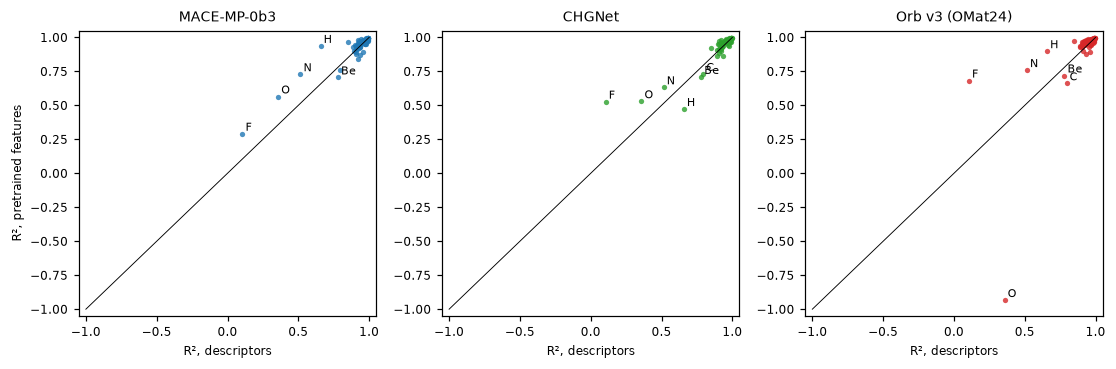

In [12]:
fig, axes = plt.subplots(1, len(METHODS) - 1, figsize=(3.4 * (len(METHODS) - 1), 3.4), squeeze=False)
for ax, m in zip(axes[0], METHODS[1:], strict=True):
    x, y = np.clip(r2_el["descriptors"], -1, 1), np.clip(r2_el[m], -1, 1)
    ax.plot([-1, 1], [-1, 1], color="k", lw=0.6)
    ax.scatter(x, y, s=12, color=COLORS[m], alpha=0.8, lw=0)
    for i, e in enumerate(elements):
        if r2_el["descriptors"][i] < 0.75 or r2_el[m][i] < 0.75:
            ax.annotate(e, (x[i], y[i]), fontsize=7, xytext=(2, 2), textcoords="offset points")
    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel("R², descriptors")
    ax.set_title(NAMES[m], fontsize=9)
axes[0][0].set_ylabel("R², pretrained features")
fig.tight_layout()
fig.savefig("figures/leave_one_element_out.png")
plt.show()

## 4. Seen during pretraining?

If the features help because the pretrained model has seen the test compounds themselves, the gain over the descriptors should be larger for test materials whose structure came from the pretraining source (Materials Project for MACE and CHGNet, Alexandria for Orb) than for the others. The test materials of a split are therefore divided by source, and for each group the MAE of the features is divided by the MAE of the descriptors on the same materials. The groups differ in more than their source (AFLOW and JARVIS's own structures are often hypothetical or two-dimensional), which is why the comparison is a ratio to the descriptors within each group rather than an MAE.

The 95 % interval comes from a cluster bootstrap: whole clusters are drawn with replacement, not single materials. The clusters are the structure types (prototype labels) for the prototype split, whose test sets are whole structure types, and the chemical systems for every other split. Materials of one cluster share much of their error, and with an element held out a compound is in the test set of each of its elements; resampling single materials treats all of them as independent and gives intervals that are too narrow (printed for comparison).

The source is a proxy for "seen", and it errs in one direction. A structure taken from AFLOW or from JARVIS itself may also be in the Materials Project, and Alexandria contains many structures derived from the Materials Project, so the group "from other sources" holds materials that the model has seen, Orb's most of all. This makes the two groups more alike: a difference found here understates the real one, and no difference does not rule out that having seen a compound helps. Materials Project entries with `mvc-` identifiers form a group of their own, because whether they are in MPtrj is not known. Groups of fewer than 100 materials are not shown.

In [13]:
SEEN = {"mace-mp-0b3": "Materials Project", "chgnet-0.3.0": "Materials Project", "orb-v3-omat": "Alexandria"}
MVC = "Materials Project (mvc)"


def cluster_ci(num, den, clusters, n_boot=2000, seed=0):
    # sum(num) / sum(den) with a 95 % interval from drawing whole clusters with replacement
    _, inv = np.unique(clusters, return_inverse=True)
    s_num, s_den = np.bincount(inv, weights=num), np.bincount(inv, weights=den)
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    for start in range(0, n_boot, 100):
        idx = rng.integers(0, len(s_num), (min(100, n_boot - start), len(s_num)))
        boot[start:start + len(idx)] = s_num[idx].sum(axis=1) / s_den[idx].sum(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return float(num.sum() / den.sum()), float(lo), float(hi)


def source_groups(m, src):
    seen, mvc = src == SEEN[m], src == MVC
    return ((f"from {SEEN[m]}", seen), ("Materials Project mvc-", mvc), ("from other sources", ~seen & ~mvc))


seen_rows = []
print(f"{'split':24s} {'features':16s} {'group':24s} {'n':>6s} {'clusters':>8s}  MAE features / descriptors, "
      "95 % interval (clusters resampled | materials resampled)")
for split in SPLITS:
    rs = rows_of(split)
    src = np.concatenate([r["src"] for r in rs])
    system = np.concatenate([r["unit"] for r in rs])
    for m in METHODS[1:]:
        ef = np.concatenate([np.abs(r["mu"][m] - r["y_test"]) for r in rs])
        ed = np.concatenate([np.abs(r["mu"]["descriptors"] - r["y_test"]) for r in rs])
        for label, mask in source_groups(m, src):
            if mask.sum() < 100:
                continue
            q, lo, hi = cluster_ci(ef[mask], ed[mask], system[mask])
            _, lo_m, hi_m = cluster_ci(ef[mask], ed[mask], np.arange(mask.sum()))
            n_sys = len(np.unique(system[mask]))
            seen_rows.append((split, m, label, int(mask.sum()), n_sys, q, lo, hi))
            print(f"{split:24s} {NAMES[m]:16s} {label:24s} {mask.sum():6d} {n_sys:8d} {q:7.3f} ({lo:.3f}-{hi:.3f} | "
                  f"{lo_m:.3f}-{hi_m:.3f})")

split                    features         group                         n clusters  MAE features / descriptors, 95 % interval (clusters resampled | materials resampled)


random                   MACE-MP-0b3      from Materials Project    43040    20636   0.909 (0.894-0.924 | 0.897-0.922)
random                   MACE-MP-0b3      Materials Project mvc-     1518      619   0.778 (0.727-0.834 | 0.731-0.828)


random                   MACE-MP-0b3      from other sources        11154     4289   1.086 (1.056-1.117 | 1.059-1.115)


random                   CHGNet           from Materials Project    43040    20636   0.843 (0.828-0.858 | 0.832-0.856)
random                   CHGNet           Materials Project mvc-     1518      619   0.721 (0.672-0.775 | 0.676-0.769)


random                   CHGNet           from other sources        11154     4289   0.902 (0.876-0.930 | 0.878-0.926)
random                   Orb v3 (OMat24)  Materials Project mvc-     1518      619   0.822 (0.757-0.891 | 0.767-0.883)


random                   Orb v3 (OMat24)  from other sources        54194    23139   0.907 (0.892-0.922 | 0.895-0.919)


... (16 outputs left out)

prospective              MACE-MP-0b3      from other sources        23838    12368   0.962 (0.941-0.986 | 0.945-0.980)


prospective              CHGNet           from Materials Project    14305     9273   0.853 (0.829-0.877 | 0.835-0.874)


prospective              CHGNet           from other sources        23838    12368   0.894 (0.875-0.912 | 0.879-0.910)
prospective              Orb v3 (OMat24)  from Alexandria            4492     3110   1.102 (1.063-1.146 | 1.065-1.141)


prospective              Orb v3 (OMat24)  from other sources        33651    16712   0.877 (0.860-0.894 | 0.863-0.891)


The same division for the energy baseline of section 3: if a model's energy transfers well because the model learned the DFT energies of the test compounds themselves, its MAE relative to the descriptors should be lowest for the materials from its pretraining source.

In [14]:
energy_seen_rows = []
print(f"{'split':24s} {'energy of':16s} {'group':24s} {'n':>6s}  MAE energy baseline / descriptors (95 % interval)")
for split in E_ROWS:
    rs = rows_of(split)
    src = np.concatenate([r["src"] for r in rs])
    unit = np.concatenate([r["unit"] for r in rs])
    ed = np.concatenate([np.abs(r["mu"]["descriptors"] - r["y_test"]) for r in rs])
    for m in E_METHODS:
        ee = np.concatenate([np.abs(r["energy_mu"][m] - r["y_test"]) for r in rs])
        for label, mask in source_groups(m, src):
            if mask.sum() < 100:
                continue
            q, lo, hi = cluster_ci(ee[mask], ed[mask], unit[mask])
            energy_seen_rows.append((split, m, label, int(mask.sum()), q, lo, hi))
            print(f"{split:24s} {NAMES[m]:16s} {label:24s} {mask.sum():6d}  {q:.3f} ({lo:.3f}-{hi:.3f})")

split                    energy of        group                         n  MAE energy baseline / descriptors (95 % interval)


random                   MACE-MP-0b3      from Materials Project    43040  1.491 (1.421-1.566)
random                   MACE-MP-0b3      Materials Project mvc-     1518  3.016 (2.618-3.410)
random                   MACE-MP-0b3      from other sources        11154  0.912 (0.881-0.944)


random                   CHGNet           from Materials Project    43040  0.798 (0.765-0.833)
random                   CHGNet           Materials Project mvc-     1518  1.150 (0.988-1.321)
random                   CHGNet           from other sources        11154  0.734 (0.710-0.761)


chemical-system groups   MACE-MP-0b3      from Materials Project    43040  1.230 (1.171-1.297)
chemical-system groups   MACE-MP-0b3      Materials Project mvc-     1518  2.319 (2.015-2.630)
chemical-system groups   MACE-MP-0b3      from other sources        11154  0.818 (0.788-0.849)


chemical-system groups   CHGNet           from Materials Project    43040  0.657 (0.628-0.687)
chemical-system groups   CHGNet           Materials Project mvc-     1518  0.876 (0.758-1.001)
chemical-system groups   CHGNet           from other sources        11154  0.658 (0.634-0.682)


prototype groups         MACE-MP-0b3      from Materials Project    43040  0.948 (0.814-1.112)
prototype groups         MACE-MP-0b3      Materials Project mvc-     1518  1.995 (1.529-2.574)
prototype groups         MACE-MP-0b3      from other sources        11154  0.415 (0.326-0.565)


prototype groups         CHGNet           from Materials Project    43040  0.506 (0.442-0.585)
prototype groups         CHGNet           Materials Project mvc-     1518  0.761 (0.599-0.966)
prototype groups         CHGNet           from other sources        11154  0.333 (0.257-0.455)
prospective              MACE-MP-0b3      from Materials Project    14305  2.059 (1.897-2.265)


prospective              MACE-MP-0b3      from other sources        23838  0.834 (0.811-0.859)
prospective              CHGNet           from Materials Project    14305  1.003 (0.923-1.105)


prospective              CHGNet           from other sources        23838  0.581 (0.567-0.595)


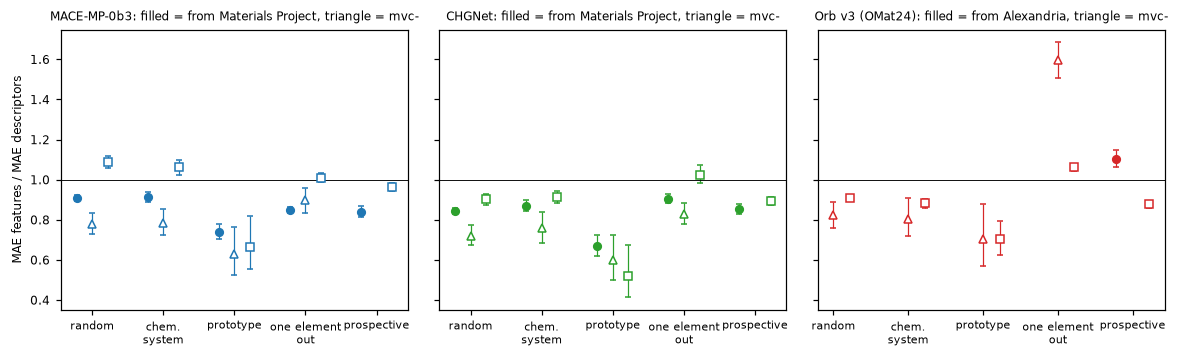

In [15]:
if seen_rows:
    fig, axes = plt.subplots(1, len(METHODS) - 1, figsize=(3.6 * (len(METHODS) - 1), 3.3), sharey=True, squeeze=False)
    for ax, m in zip(axes[0], METHODS[1:], strict=True):
        labels = [label for label, _ in source_groups(m, SRC[:0])]
        for j, split in enumerate(SPLITS):
            for k, (label, marker) in enumerate(zip(labels, "o^s", strict=True)):
                row = [s for s in seen_rows if s[0] == split and s[1] == m and s[2] == label]
                if row:
                    q, lo, hi = row[0][-3:]
                    ax.errorbar(j + (k - 1) * 0.22, q, yerr=[[q - lo], [hi - q]], fmt=marker, color=COLORS[m],
                                mfc=COLORS[m] if k == 0 else "white", ms=5, capsize=2, lw=0.8)
        ax.axhline(1, color="k", lw=0.6)
        ax.set_xticks(range(len(SPLITS)), [s.replace(" groups", "").replace("chemical-system", "chem.\nsystem")
                                           .replace("leave one element out", "one element\nout") for s in SPLITS],
                      fontsize=7)
        ax.set_title(f"{NAMES[m]}: filled = from {SEEN[m]}, triangle = mvc-", fontsize=8)
    axes[0][0].set_ylabel("MAE features / MAE descriptors")
    fig.tight_layout()
    fig.savefig("figures/seen_in_pretraining.png")
    plt.show()

## 5. Orientation: Orb's features with every structure rotated

Every structure turned by its own random rotation, the Orb features computed again, and the downstream ensembles fitted again on six test sets (the first fold of each cross-validation, and F, O and Cu held out: two of the hardest elements and one typical one). If the orientation in which JARVIS stores the structures carried information, the error would change.

Both fits predict the same test materials, so the difference of the MAEs (rotated minus stored) gets a paired 95 % interval, from resampling whole clusters as in section 4. One random rotation per structure is one draw: an interval that contains zero means that no effect of the orientation was found on that test set.

In [16]:
rot_rows = []
if "orb-v3-omat-rotated" in FEAT:
    print(f"{'test set':12s} {'MAE, stored orientation':>24s} {'MAE, rotated':>13s} {'difference (95 % interval)':>34s} "
          f"{'correlation of predictions':>27s}")
    for t in runs.tasks(d, "orb-v3-omat-rotated"):
        res = runs.fit(d, "orb-v3-omat-rotated", t, FEAT["orb-v3-omat-rotated"], compute=not QUICK)
        if res is None or t.key not in R or "orb-v3-omat" not in R[t.key]["mu"]:
            continue
        r = R[t.key]
        a, b = mae(r, "orb-v3-omat"), float(np.mean(np.abs(res[0]["test_mu"] - r["y_test"])))
        diff = np.abs(res[0]["test_mu"] - r["y_test"]) - np.abs(r["mu"]["orb-v3-omat"] - r["y_test"])
        _, lo, hi = cluster_ci(diff, np.ones_like(diff), r["unit"])
        rot_rows.append((t.key, a, b, lo, hi))
        print(f"{t.key:12s} {a:24.4f} {b:13.4f} {b - a:+12.4f} ({lo:+.4f} to {hi:+.4f}) "
              f"{np.corrcoef(r['mu']['orb-v3-omat'], res[0]['test_mu'])[0, 1]:27.4f}")

test set      MAE, stored orientation  MAE, rotated         difference (95 % interval)  correlation of predictions


random-0                       0.0807        0.0811      +0.0004 (-0.0008 to +0.0016)                      0.9988
chemical-0                     0.0950        0.0977      +0.0027 (+0.0011 to +0.0044)                      0.9989
prototype-0                    0.1117        0.1146      +0.0028 (-0.0029 to +0.0038)                      0.9973


element-O                      1.1724        1.1750      +0.0027 (-0.0001 to +0.0056)                      0.9921
element-F                      0.4509        0.4552      +0.0044 (-0.0004 to +0.0092)                      0.9971
element-Cu                     0.1432        0.1438      +0.0005 (-0.0017 to +0.0029)                      0.9975


## 6. Does the ensemble know when it is wrong?

The spread of the five gradient-boosting models, as in the `uncertainty` experiment: Spearman correlation between the standard deviation and the absolute error (median over the test sets of a split), and the coverage of conformal 90 % intervals scaled by it.

In [17]:
uq_rows = {}
print(f"{'split':24s} " + " ".join(f"{NAMES[m] + ' rho / cover':>30s}" for m in METHODS))
for split in SPLITS:
    rs = [r for r in R.values() if r["split"] == split]
    cells_ = []
    for m in METHODS:
        rho = np.median([uq.spearman(r["sd"][m], np.abs(r["mu"][m] - r["y_test"])) for r in rs])
        cover = []
        for r in rs:
            scores = uq.residual_scores(r["y_cal"], r["cal_mu"][m], r["cal_sd"][m])
            lo, hi = uq.conformal_interval(r["mu"][m], scores, ALPHA, scale=r["sd"][m])
            cover.append(uq.interval_coverage(r["y_test"], lo, hi))
        uq_rows[(split, m)] = (float(rho), float(np.mean(cover)))
        cells_.append(f"{rho:20.2f} / {np.mean(cover):.3f}")
    print(f"{split:24s} " + " ".join(cells_))

split                     descriptors (150) rho / cover        MACE-MP-0b3 rho / cover             CHGNet rho / cover    Orb v3 (OMat24) rho / cover
random                                   0.54 / 0.899                 0.49 / 0.900                 0.50 / 0.900                 0.49 / 0.900
chemical-system groups                   0.47 / 0.902                 0.37 / 0.898                 0.37 / 0.899                 0.39 / 0.902


prototype groups                         0.46 / 0.892                 0.40 / 0.899                 0.41 / 0.902                 0.41 / 0.900


leave one element out                    0.27 / 0.807                 0.24 / 0.806                 0.25 / 0.788                 0.26 / 0.826
prospective                              0.49 / 0.868                 0.46 / 0.887                 0.46 / 0.879                 0.43 / 0.868


## 7. Summary

In [18]:
print(f"{'quantity':80s} {'this run':>12s} {'check':>16s}  from")
for q, v, c, src in summary:
    print(f"{q:80s} {v:>12s} {c:>16s}  {src}")

quantity                                                                             this run            check  from
Orb features under rotation: 99th percentile of change / spread                          0.41 0 for an invariant model  this notebook
MAE random split, MACE-MP-0b3 features (descriptors 0.088)                             0.0840     CGCNN 0.0563  this repository
MAE random split, CHGNet features (descriptors 0.088)                                  0.0752     CGCNN 0.0563  this repository
MAE random split, Orb v3 (OMat24) features (descriptors 0.088)                         0.0794     CGCNN 0.0563  this repository
MAE random split, MACE-MP-0b3 energy + one correction per element                      0.1197  features 0.0840  this notebook
MAE random split, CHGNet energy + one correction per element                           0.0693  features 0.0752  this notebook
E_CHGNet - E_MACE per O atom, oxides without F or a +U metal                           -0.680    MP2020 -0.687  p

In [19]:
export = {
    "about": "Frozen features of pretrained universal interatomic potentials with the gradient-boosting ensemble of "
             "the uncertainty experiment; JARVIS-DFT formation energy",
    "models": pretrained.MODELS,
    "mae": mae_table,
    "elements": [{"element": e, "n": len(EL[e]["y_test"]), **{f"r2_{m}": float(r2_el[m][i]) for m in METHODS},
                  **{f"mae_{m}": float(mae_el[m][i]) for m in METHODS}} for i, e in enumerate(elements)],
    "cgcnn_elements": {"elements": list(cg_el), "mae": {NAMES.get(m, m): [float(x) for x in v] for m, v in table12.items()}},
    "energy_baseline": energy_table,
    "energy_baseline_by_source": [dict(zip(("split", "model", "group", "n", "ratio", "lo", "hi"), row, strict=True))
                                  for row in energy_seen_rows],
    "seen_in_pretraining": [dict(zip(("split", "model", "group", "n", "systems", "ratio", "lo", "hi"), row, strict=True))
                            for row in seen_rows],
    "rotation": [dict(zip(("task", "mae_stored", "mae_rotated", "difference_lo", "difference_hi"), row, strict=True))
                 for row in rot_rows],
    "invariance": [{"model": k[0], "change": k[1], "median": v[0], "p99": v[1], "max": v[2]} for k, v in invariance.items()],
    "uncertainty": [{"split": k[0], "method": k[1], "spearman_median": v[0], "coverage_normalized": v[1]}
                    for k, v in uq_rows.items()],
    "settings": {"features": runs.FEATURE_SETTINGS, "fit": runs.FIT_SETTINGS},
}
with open("pretrained_features_results.json", "w", encoding="utf-8") as f:
    json.dump(export, f, indent=1, default=float)
print("written pretrained_features_results.json")

written pretrained_features_results.json


## Discussion

**The features are the models' own.** They agree with each package's outputs (MACE's descriptors, CHGNet's crystal feature and energy, Orb's calculator energy) to float32 rounding. MACE's and CHGNet's features are invariant to atom order, cell choice, rotations and reflections; Orb's to order and cell, but not to rotations: at the 99th percentile a rotation changes a feature by 0.41 of its spread between materials, by up to 2.8 times, while Orb's energy changes by at most 5 × 10⁻⁴ eV/atom. Fitted again with every structure turned, six test sets changed their MAE by 0.2–3 % (predictions correlated at 0.992 or more); the paired 95 % interval excludes zero only for the first chemical-system fold (+2.9 %). The orientation in which JARVIS stores the structures does not drive the results.

**Frozen features beat the descriptors, but not a network trained on the task.** With the same gradient-boosting ensemble, the features of all three models beat the 150 descriptors on every fold of every cross-validation and on the prospective test (except one chemical-system fold for MACE): 4–14 % lower MAE on the random split and 29–39 % lower on new structure types, where the loss under shift falls from 1.79 times the random-split MAE to 1.28–1.39 times. CGCNN trained from scratch on the same materials is better still on all these splits (0.056 eV/atom random, 0.084 on new structure types, against 0.075–0.084 and 0.096–0.111): a representation pretrained for energies and forces, read by gradient boosting, leaves much of what end-to-end training on the target gets.

**For CHGNet, the pretrained energy does better than the features.** CHGNet's energy per atom with one linear correction per element, fitted by least squares on the training materials of each test set, reaches 0.069 eV/atom on the random split, against 0.075 for gradient boosting on CHGNet's features and 0.088 on the descriptors, and it hardly degrades under shift: 0.070 on new chemical systems, 0.070 on new structure types and 0.079 on the materials added later. On new structure types it has the lowest error of any method here, CGCNN included (0.084); on the other splits CGCNN stays ahead (0.056, 0.062, 0.073). The coefficient of the energy is 1.003–1.012 on every test set: CHGNet's energy differences between materials are those of JARVIS up to one constant per element. The same baseline with MACE's energy is worse than the descriptors on every split but new structure types (0.120–0.129 eV/atom). The difference between the two models' energies shows why. Regressed on the fractions of oxygen, fluorine and the +U metals in oxides and fluorides, it reproduces the MP2020 corrections of Materials Project: −0.680 eV per oxygen atom in oxides without a +U metal (MP2020: −0.687), within 0.01 eV per atom of V, Cr, Mn and W and within 0.11 eV of Co, Fe, Ni and Mo, and a median of −0.002 eV/atom for materials without any corrected species. CHGNet learned the MP2020-corrected energies, MACE-MP-0b3 the uncorrected mixture of PBE and PBE+U. The anion corrections are proportional to the fraction of oxygen or fluorine and are absorbed by the per-element terms, but the +U corrections apply to a metal only in its oxides and fluorides, which one constant per element cannot represent. CHGNet's advantage does not come from the materials it was pretrained on: relative to the descriptors its energy does as well or better on the materials from other sources than on those from Materials Project (MAE ratio 0.73 against 0.80 on the random split, 0.33 against 0.51 on new structure types, 0.58 against 1.00 on the materials added later).

**With an element held out, pretraining helps on average, not uniformly.** Over all 78 held-out elements the mean MAE falls from 0.160 to 0.137–0.148 eV/atom, and the features are better on 48 (MACE), 54 (CHGNet) and 61 (Orb) of the 78. On the 12 elements of the `cgcnn` experiment the features of MACE and CHGNet beat both the descriptors and CGCNN (mean MAE 0.258 and 0.281 against 0.303 and 0.382). Fluorides gain the most: R² 0.11 rises to 0.29, 0.53 and 0.68, and the MAE falls from 0.75 to 0.70, 0.55 and 0.45 eV/atom (CGCNN: 1.24). But no feature set is better everywhere. Hydrides are predicted far better with MACE's and Orb's features (R² 0.94 and 0.90 against 0.66) and worse with CHGNet's (0.47); oxides fail with Orb's features (R² −0.93, all overestimated by 1.17 eV/atom on average) although Orb was pretrained on oxides; beryllium and carbon compounds are predicted worse by all three. The hard elements stay hard: the per-element R² of the features ranks the elements like that of the descriptors (Spearman 0.77–0.81).

**The gain of the MPtrj models' features sits on Materials Project structures.** For MACE-MP-0b3 the features beat the descriptors on test materials whose starting structure came from Materials Project (MAE ratio 0.91 on the random split, 0.85 with elements held out, 0.84 on the materials added later) and not on the others (1.09, 1.01, 0.96); CHGNet shows the same direction, less strongly (0.84 against 0.90, 0.90 against 1.02, 0.85 against 0.89). On new structure types the intervals, which resample whole structure types, are wide and overlap. Orb, pretrained on data derived from Alexandria, is worse than the descriptors on the Alexandria-sourced materials added after 2021 (1.10 against 0.88 for the others). So much of what the MPtrj models add for an unseen element is added for compounds whose structures, and possibly whose PBE energies, were in their pretraining data. The source labels cannot tell memorization from a better coverage of Materials-Project-like chemistry, because the groups differ in what they hold: 43 % of the Materials-Project-sourced materials of the 2021 snapshot have an ICSD entry (an experimentally reported compound), none of the materials from the other sources do.

**The uncertainty does not improve.** The spread of the five gradient-boosting models ranks the errors slightly worse on the features than on the descriptors (median Spearman 0.43–0.50 against 0.49–0.54 on the random and prospective test sets, 0.37–0.41 against 0.46–0.47 on the group splits, 0.24–0.26 against 0.27 with an element held out), and conformal intervals scaled by it cover about the same.

**Caveats.** The models are used frozen, with gradient boosting on the mean and standard deviation of their last-layer atom features; fine-tuning, a neural readout or other layers might do better. One checkpoint of each model was used, and the downstream models were not tuned. Whether a test compound is in a pretraining set is inferred from where JARVIS took its structure, not checked against MPtrj or OMat24. The energy baseline uses each model's energy as it comes; MACE's energy with the MP2020 corrections applied, and Orb's energy, were not tried, and it cannot be applied with an element held out.

Pretraining on every element narrows the gap that `cgcnn` found for unseen elements, most clearly for fluorides and hydrides, but it is not a general fix: which elements improve depends on the model, one model fails badly on oxides, and for the MPtrj models the gain of the features concentrates on compounds that come from their own pretraining source. The most robust transfer here goes through the energy, not the features: CHGNet's MP2020-corrected energy, with one constant per element, predicts JARVIS formation energies of new structure types and of later materials almost as well as on a random split.